# 07 · Projecting UK lending losses under the Bank of England 2025 stress scenario

**The question this project set out to answer:** if the UK enters the Bank of England's 2025 Bank Capital Stress Test scenario, how much would lenders lose on credit cards, other consumer credit, mortgages and corporate lending, and how sure can we be?

The scenario: UK GDP −5%, unemployment rising to 8.5%, house prices −28%, Bank Rate 8%, starting from the end-2024 position.

**Approach**
1. Project each champion model over 2025–29 with 2,000 simulations (parameter draws from the Newey–West covariance, block-bootstrapped residuals)
2. Convert loss rates to £ on a static balance sheet (end-2024 balances), as the Bank of England does
3. Report **ranges, not points**: jump-off anchoring, challenger models, transform choice and a credit-quality overlay
4. Benchmark against the Bank of England's own published results
5. Reverse stress test: how severe a recession would it take to exceed the 2009–10 crisis peaks?

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ukstress.config import MODELS_DIR, PORTFOLIOS, PROCESSED_DIR
from ukstress.features.build import JUMP_OFF, inv_logit_pct, logit_pct, scaled_scenario, scenario_macro, trailing_loss_rate
from ukstress.ingest.build_panel import build_macro, build_panel
from ukstress.models.satellite import fit, load_models, project, target
from ukstress.scenarios.engine import anchor, cumulative, jump_off_balances, jump_off_gap, run, summary_table
from ukstress.validation.backtest import BOE_2025_IMPAIRMENT_RATES, BOE_SOURCE, backtest
from ukstress.viz import GREY, ORANGE, PORTFOLIO_COLOURS, fig_title, save, set_style, subtitle

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 200, "display.precision", 2, "display.max_colwidth", 60)

panel, macro = build_panel(), build_macro()
path = scenario_macro(macro)
champions = load_models(MODELS_DIR / "champions.json")
challengers = load_models(MODELS_DIR / "challengers.json")
panel_ch = load_models(MODELS_DIR / "panel_challengers.json")
LABEL = {p: s["label"] for p, s in PORTFOLIOS.items()}

## 1. Central projection with simulation bands

In [2]:
paths = run(champions, panel, macro, path, n_sims=2000, seed=7)
table = summary_table(paths, panel)
table.T

,credit_card,other_consumer,mortgage,corporate
loss rate at jump-off %,2.29,0.76,0.01,0.13
peak loss rate %,6.37,2.37,0.22,1.08
peak quarter,2028Q1,2028Q1,2028Q1,2028Q1
5-year cumulative %,24.36,7.05,0.53,3.65
balance £bn,53.08,74.86,1473.97,499.64
5-year losses £bn,12.93,5.28,7.84,18.21
losses if rates stayed at jump-off £bn,6.07,2.85,0.4,3.14
5-year cumulative 5th pct %,17.48,2.97,0.24,2.27
5-year cumulative 95th pct %,34.78,13.65,1.22,5.61
stress uplift £bn,6.86,2.43,7.44,15.07


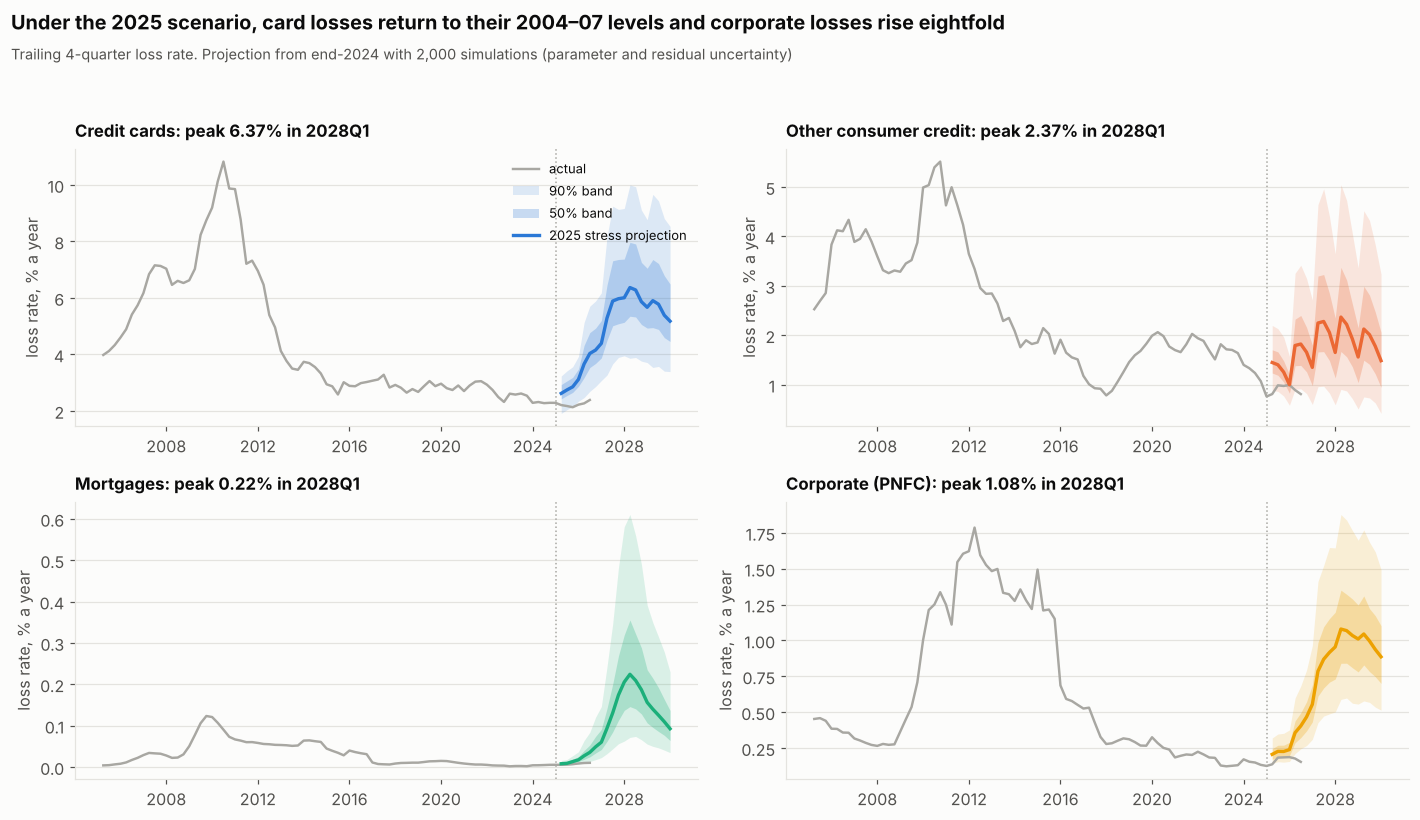

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, p in zip(axes.flat, PORTFOLIOS):
    pr = paths[p]
    hist = trailing_loss_rate(panel, p).loc["2005Q1":]
    t = pr.index.to_timestamp(how="end")
    ax.plot(hist.index.to_timestamp(how="end"), hist, color=GREY, lw=1.6, label="actual")
    ax.fill_between(t, pr.p05, pr.p95, color=PORTFOLIO_COLOURS[p], alpha=0.15, lw=0, label="90% band")
    ax.fill_between(t, pr.p25, pr.p75, color=PORTFOLIO_COLOURS[p], alpha=0.25, lw=0, label="50% band")
    ax.plot(t, pr.central, color=PORTFOLIO_COLOURS[p], lw=2.2, label="2025 stress projection")
    ax.axvline(JUMP_OFF.end_time, color=GREY, ls=":", lw=1)
    ax.set_title(f"{LABEL[p]}: peak {pr.central.max():.2f}% in {pr.central.idxmax()}", fontsize=11, pad=8)
    ax.set_ylabel("loss rate, % a year")
axes[0, 0].legend(loc="upper right", fontsize=8.5)
fig_title(fig, "Under the 2025 scenario, card losses return to their 2004–07 levels and corporate losses rise eightfold",
          "Trailing 4-quarter loss rate. Projection from end-2024 with 2,000 simulations (parameter and residual uncertainty)")
save(fig, "07_scenario_fan_charts")
fig

The saw-tooth in the other-consumer projection is mechanical, not economic. That model links each quarter only to the *same quarter a year earlier* (its persistence term is the loss rate four quarters back), so the quarter-to-quarter pattern of 2024 echoes through every later year, fading at the rate ρ = 0.86. Annual figures (section 2) are unaffected.

## 2. In pounds: a static end-2024 balance sheet

In [4]:
gbp = table[["balance £bn", "5-year cumulative %", "5-year cumulative 5th pct %", "5-year cumulative 95th pct %",
             "5-year losses £bn", "losses if rates stayed at jump-off £bn", "stress uplift £bn"]].astype(float)
gbp.index = [LABEL[p] for p in gbp.index]
gbp.loc["Total"] = gbp.sum()
for c in ["5-year cumulative %", "5-year cumulative 5th pct %", "5-year cumulative 95th pct %"]:
    gbp.loc["Total", c] = 100 * (gbp[c].iloc[:-1] / 100 * gbp["balance £bn"].iloc[:-1]).sum() / gbp.loc["Total", "balance £bn"]
gbp.round(2)

,balance £bn,5-year cumulative %,5-year cumulative 5th pct %,5-year cumulative 95th pct %,5-year losses £bn,losses if rates stayed at jump-off £bn,stress uplift £bn
Credit cards,53.08,24.36,17.48,34.78,12.93,6.07,6.86
Other consumer credit,74.86,7.05,2.97,13.65,5.28,2.85,2.43
Mortgages,1473.97,0.53,0.24,1.22,7.84,0.40,7.44
Corporate (PNFC),499.64,3.65,2.27,5.61,18.21,3.14,15.07
Total,2101.55,2.11,1.26,3.56,44.26,12.46,31.80


Five-year write-offs across the four portfolios total about **£44 billion** under the scenario, of which roughly £32 billion is the stress uplift over what end-2024 loss rates would have produced anyway. Corporate lending is the largest £ loss (a big book with a rising loss rate); cards have the highest loss *rate*. Mortgages have a tiny rate but £1.5 trillion of balances, so even 0.5% cumulative is about £8 billion.

Percentile columns are proper percentiles of each portfolio's five-year cumulative loss across simulations. The "Total" percentiles are a simple balance-weighted sum and therefore assume the portfolios' errors move together (a conservative upper envelope).

## 3. Model-risk range: how much does the answer depend on modelling choices?
Each row changes one choice and keeps the rest.
- **Jump-off anchored:** start each projection from the actual end-2024 loss rate (gap fades over 8 quarters)
- **Challenger:** best passing model on different drivers (notebook 03)
- **Pooled consumer panel:** other-consumer slopes estimated jointly with cards (notebook 05)
- **Raw-rate transform:** card model on the untransformed rate (notebook 04)
- **Credit-quality overlay:** consumer projections scaled down by the ratio of actual to modelled losses over 2025–26 (notebook 06, live monitoring), reflecting improved book quality

In [5]:
variants = {"Champion": {p: cumulative(paths[p].central) for p in PORTFOLIOS}}
anch = run(champions, panel, macro, path, anchored=True)
variants["Jump-off anchored"] = {p: cumulative(anch[p].central) for p in PORTFOLIOS}
variants["Challenger"] = {p: cumulative(project(challengers[p], target(panel, p), path).central) for p in challengers}
variants["Pooled consumer panel"] = {"other_consumer": cumulative(project(panel_ch["other_consumer"],
                                                                         target(panel, "other_consumer"), path).central)}
raw_y = trailing_loss_rate(panel, "credit_card").rename("y")
fm_raw, _ = fit(champions["credit_card"].spec, raw_y, macro)
z = project(fm_raw, raw_y, path).central  # project() applies inverse-logit; undo it to read the raw-rate model
variants["Raw-rate transform"] = {"credit_card": cumulative(np.log((z / 100) / (1 - z / 100)))}

overlay = {}
for p in ["credit_card", "other_consumer"]:
    live = backtest(champions[p].spec, panel, macro, "2024Q4", horizon=6, n_sims=0)
    overlay[p] = float((live.actual / live.central).mean())
variants["Credit-quality overlay"] = {p: cumulative(paths[p].central) * overlay[p] for p in overlay}
mr = pd.DataFrame(variants).T[list(PORTFOLIOS)].rename(columns=LABEL)
print("Overlay factors (actual / model, 2025Q1–2026Q2):", {LABEL[p]: round(v, 2) for p, v in overlay.items()})
mr.round(2)

Overlay factors (actual / model, 2025Q1–2026Q2): {'Credit cards': 0.72, 'Other consumer credit': 0.62}


,Credit cards,Other consumer credit,Mortgages,Corporate (PNFC)
Champion,24.36,7.05,0.53,3.65
Jump-off anchored,24.20,6.60,0.53,3.56
Challenger,22.40,6.32,0.37,3.42
Pooled consumer panel,NaN,9.27,NaN,NaN
Raw-rate transform,29.39,NaN,NaN,NaN
Credit-quality overlay,17.60,4.37,NaN,NaN


In [6]:
rng_tab = pd.DataFrame({"champion %": mr.loc["Champion"], "low %": mr.min(), "high %": mr.max()})
bal = jump_off_balances(panel).rename(index=LABEL)
rng_tab["champion £bn"] = rng_tab["champion %"] / 100 * bal
rng_tab["low £bn"] = rng_tab["low %"] / 100 * bal
rng_tab["high £bn"] = rng_tab["high %"] / 100 * bal
rng_tab.loc["Total", ["champion £bn", "low £bn", "high £bn"]] = rng_tab[["champion £bn", "low £bn", "high £bn"]].sum()
rng_tab.round(2)

,champion %,low %,high %,champion £bn,low £bn,high £bn
Credit cards,24.36,17.60,29.39,12.93,9.34,15.60
Other consumer credit,7.05,4.37,9.27,5.28,3.27,6.94
Mortgages,0.53,0.37,0.53,7.84,5.48,7.84
Corporate (PNFC),3.65,3.42,3.65,18.21,17.10,18.21
Total,NaN,NaN,NaN,44.26,35.20,48.60


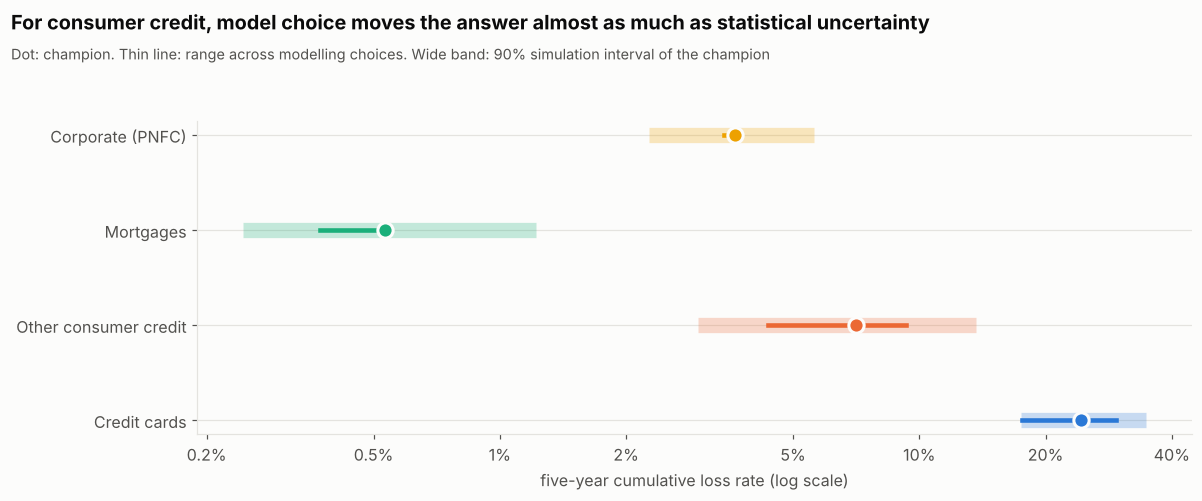

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6))
y0 = np.arange(len(PORTFOLIOS))
for i, p in enumerate(PORTFOLIOS):
    r = rng_tab.loc[LABEL[p]]
    sims_q = table.loc[p, ["5-year cumulative 5th pct %", "5-year cumulative 95th pct %"]].astype(float)
    ax.plot([sims_q.iloc[0], sims_q.iloc[1]], [i, i], color=PORTFOLIO_COLOURS[p], lw=10, alpha=0.25, solid_capstyle="butt")
    ax.plot([r["low %"], r["high %"]], [i, i], color=PORTFOLIO_COLOURS[p], lw=3)
    ax.plot(r["champion %"], i, "o", color=PORTFOLIO_COLOURS[p], ms=10, mec="#fcfcfb", mew=2)
ax.set_yticks(y0, [LABEL[p] for p in PORTFOLIOS])
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([0.2, 0.5, 1, 2, 5, 10, 20, 40]))
ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set_xlabel("five-year cumulative loss rate (log scale)")
fig_title(fig, "For consumer credit, model choice moves the answer almost as much as statistical uncertainty",
          "Dot: champion. Thin line: range across modelling choices. Wide band: 90% simulation interval of the champion")
save(fig, "07_model_risk_range")
fig

## 4. Benchmark: how do these compare with the Bank of England's own results?
The Bank published five-year impairment rates for the seven participating banks in the December 2025 *Financial Stability Report* (Table 5.C). Impairment rate = five-year impairment charge ÷ average gross exposure.

In [8]:
w = jump_off_balances(panel)
consumer = (cumulative(paths["credit_card"].central) * w["credit_card"]
            + cumulative(paths["other_consumer"].central) * w["other_consumer"]) / (w["credit_card"] + w["other_consumer"])
consumer_ol = (variants["Credit-quality overlay"]["credit_card"] * w["credit_card"]
               + variants["Credit-quality overlay"]["other_consumer"] * w["other_consumer"]) / (w["credit_card"] + w["other_consumer"])
total = (gbp.loc["Total", "5-year losses £bn"] / gbp.loc["Total", "balance £bn"]) * 100
bench = pd.DataFrame({
    "this project: write-off rate %": [consumer, cumulative(paths["mortgage"].central), total],
    "Bank of England 2025: impairment rate %": [BOE_2025_IMPAIRMENT_RATES["UK consumer credit"],
                                                BOE_2025_IMPAIRMENT_RATES["UK mortgages"],
                                                BOE_2025_IMPAIRMENT_RATES["Total UK"]],
}, index=["UK consumer credit (cards + other)", "UK mortgages", "Total (these four portfolios vs all UK lending)"])
bench["ratio"] = bench.iloc[:, 0] / bench.iloc[:, 1]
print(f"Source: {BOE_SOURCE} (Table 5.C)")
bench.round(2)

Source: https://www.bankofengland.co.uk/financial-stability-report/2025/december-2025 (Table 5.C)


,this project: write-off rate %,Bank of England 2025: impairment rate %,ratio
UK consumer credit (cards + other),14.23,23.3,0.61
UK mortgages,0.53,1.0,0.53
Total (these four portfolios vs all UK lending),2.11,3.8,0.55


**Reading the benchmark.** The two numbers measure different things, so they should not match. They should differ in a predictable direction, and they do:

1. **Impairments exceed write-offs within a five-year window.** Under IFRS 9, banks book lifetime expected losses as soon as credit deteriorates, including for loans still being repaid at the end of the horizon; write-offs come only when debt is finally written off, months or years later. Impairment rates should therefore be **higher** than write-off rates in a stress, as they are for both consumer credit (about 1.6x) and mortgages (about 2x).
2. **Population:** the Bank's figures cover the seven largest banks' UK books; the write-off data cover all UK banks and building societies, including lower-risk building-society mortgage books.
3. **Judgement:** the Bank cut its consumer impairment rate by an estimated 4.6 percentage points by removing past judgements, reflecting better consumer credit quality (Box E). This project's live monitoring found the same pattern independently: the consumer models over-predicted 2025–26.

The ordering of risk is the same in both: consumer credit an order of magnitude riskier than mortgages, and mortgage rates of around 1% or less even with house prices down 28%.

## 5. Reverse stress test: how bad would a recession need to be?
Scale every scenario deviation from the end-2024 position by a severity factor *k* (k = 1 is the Bank of England scenario; k = 0 holds the economy at end-2024). Which *k* would push each portfolio's peak loss rate above its 2009–12 crisis peak?

In [9]:
gfc_peak = {p: trailing_loss_rate(panel, p).loc["2008Q1":"2012Q4"].max() for p in PORTFOLIOS}
ks = np.round(np.arange(0, 2.51, 0.1), 2)
curve = {}
for k in ks:
    sp = scaled_scenario(path, k)
    curve[k] = {p: project(champions[p], target(panel, p), sp).central.max() for p in PORTFOLIOS}
    curve[k]["peak unemployment"] = sp.loc[sp.index > JUMP_OFF, "unemployment"].max()
    curve[k]["peak Bank Rate"] = sp.loc[sp.index > JUMP_OFF, "bank_rate"].max()
curve = pd.DataFrame(curve).T
breach = {}
for p in PORTFOLIOS:
    over = curve.index[curve[p] > gfc_peak[p]]
    k = over.min() if len(over) else None
    breach[LABEL[p]] = {"crisis peak %": gfc_peak[p], "k needed": k,
                        "peak unemployment at that k": curve.loc[k, "peak unemployment"] if k is not None else None,
                        "peak Bank Rate at that k": curve.loc[k, "peak Bank Rate"] if k is not None else None}
pd.DataFrame(breach).T

,crisis peak %,k needed,peak unemployment at that k,peak Bank Rate at that k
Credit cards,10.83,2.0,12.60,11.14
Other consumer credit,5.51,NaN,NaN,NaN
Mortgages,0.12,0.8,7.68,7.37
Corporate (PNFC),1.79,1.4,10.14,9.26


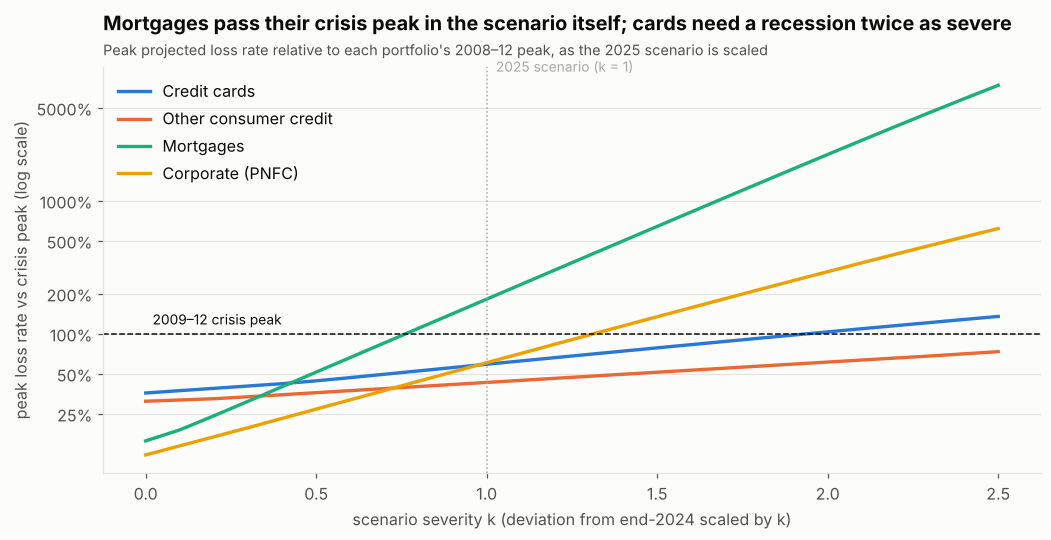

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for p in PORTFOLIOS:
    ax.plot(curve.index, curve[p] / gfc_peak[p] * 100, color=PORTFOLIO_COLOURS[p], lw=2.2, label=LABEL[p])
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator([25, 50, 100, 200, 500, 1000, 5000]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))
ax.axhline(100, color="#0b0b0b", ls="--", lw=1)
ax.axvline(1, color=GREY, ls=":", lw=1)
ax.annotate("2025 scenario (k = 1)", (1, ax.get_ylim()[1] * 0.92), xytext=(6, 0), textcoords="offset points", color=GREY, fontsize=9)
ax.annotate("2009–12 crisis peak", (0.02, 100), xytext=(0, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("scenario severity k (deviation from end-2024 scaled by k)")
ax.set_ylabel("peak loss rate vs crisis peak (log scale)")
ax.legend(loc="upper left")
ax.set_title("Mortgages pass their crisis peak in the scenario itself; cards need a recession twice as severe")
subtitle(ax, "Peak projected loss rate relative to each portfolio's 2008–12 peak, as the 2025 scenario is scaled")
save(fig, "07_reverse_stress")
fig

**Reading the reverse stress test**
- **Mortgages** exceed their 2008–12 peak already at 80% of the scenario's severity. The difference from 2009 is interest rates: Bank Rate was cut to 0.5% then, while the scenario raises it to 8%. The mortgage model's Bank Rate effect (a two-year lag) carries that straight into arrears and write-offs. This is the clearest case of the extrapolation risk flagged in the EDA: no UK data since 1993 combine high unemployment with an 8% Bank Rate.
- **Corporate** losses pass their crisis peak at 1.4x severity (unemployment about 10%).
- **Cards** need a recession twice as severe as the scenario (unemployment about 12.6%, Bank Rate about 11%) to exceed their 2009–10 peak.
- **The mortgage curve explodes at high severity** (70 times its crisis peak at k = 2.5): the logit model compounds an 11%+ Bank Rate and very high unemployment far outside any observed data. Beyond about k = 1.5, mortgage projections are extrapolation and should not be read literally.
- **Other consumer credit** stays below its crisis peak even at 2.5x severity. Its single-driver model responds only to the *change* in unemployment, so it fades even while unemployment stays high (validation rated it amber, weak).

## 6. Reality check: what has actually happened since the jump-off?
The scenario is hypothetical; the economy did not follow it. Unemployment rose to about 5% rather than 7%, and Bank Rate fell rather than rising to 8%.

In [11]:
real = pd.DataFrame({
    "scenario unemployment": path.loc["2025Q1":"2026Q2", "unemployment"],
    "actual unemployment": macro.loc["2025Q1":"2026Q2", "unemployment"],
    "scenario Bank Rate": path.loc["2025Q1":"2026Q2", "bank_rate"],
    "actual Bank Rate": macro.loc["2025Q1":"2026Q2", "bank_rate"],
    "projected card loss %": paths["credit_card"].central.loc["2025Q1":"2026Q2"],
    "actual card loss %": trailing_loss_rate(panel, "credit_card").loc["2025Q1":"2026Q2"],
})
real.round(2)

,scenario unemployment,actual unemployment,scenario Bank Rate,actual Bank Rate,projected card loss %,actual card loss %
quarter,,,,,,
2025Q1,4.9,4.6,6.00,4.60,2.62,2.21
2025Q2,5.4,4.7,6.90,4.35,2.74,2.17
2025Q3,5.8,5.0,7.50,4.10,2.85,2.13
2025Q4,6.3,5.2,8.00,3.97,3.12,2.22
2026Q1,6.8,5.0,7.85,3.75,3.66,2.27
2026Q2,7.2,4.9,7.50,3.75,4.03,2.39


## 7. Save outputs for the dashboard and documentation

In [12]:
out = []
for p, pr in paths.items():
    d = pr[[c for c in pr.columns if c in ["central", "p05", "p25", "p50", "p75", "p95"]]].copy()
    d.attrs = {}
    d["portfolio"] = p
    out.append(d.reset_index().rename(columns={"index": "quarter"}))
proj_df = pd.concat(out)
proj_df["quarter"] = proj_df["quarter"].astype(str)
proj_df.to_csv(MODELS_DIR / "scenario_projections.csv", index=False)
gbp.round(3).to_csv(MODELS_DIR / "scenario_losses.csv")
rng_tab.round(3).to_csv(MODELS_DIR / "model_risk_range.csv")
print("saved: models/scenario_projections.csv, scenario_losses.csv, model_risk_range.csv")

saved: models/scenario_projections.csv, scenario_losses.csv, model_risk_range.csv


## Conclusions
The executive answer is written up in `docs/executive_summary.md` from the tables above.